# 11 — Reverse Causation Check: Does Price Momentum Lead Future Rate-of-Change?

**Purpose.** Tests the *reverse* direction from `06_eda.ipynb`: does county price momentum
predict *future* mortgage rate-of-change, rather than the direction notebook 06 already tested
(does rate-of-change predict future decline risk)?

**Why this notebook exists.** Notebook 06's lag sweep found that `mortgage_rate_roc` is most
correlated with next-quarter decline risk at a 12-month lag, but with a **negative** sign
(r = -0.0521, 95% CI [-0.0568, -0.0474]) -- the opposite of the positive sign the stated
hypothesis expected (rising rates -> higher borrowing cost -> more decline risk). See
`outputs/eda_summary.json` (`sign_matches_hypothesis: false`). This was flagged at the time as
a face-validity surprise, not smoothed over.

A plausible explanation, written into `notebooks/10_final_evaluation.ipynb`'s Final write-up
as a stated limitation (the "Option A" paragraph): the Federal Reserve doesn't set mortgage
rate policy in a vacuum -- it responds to economic conditions, including a cooling housing
market. So part of the observed correlation plausibly runs in both directions at once, a
feedback loop rather than a one-way causal arrow.

**This notebook investigates that explanation directly**, rather than leaving it as an
untested story. It does not re-derive anything notebook 06 already settled, and it does not
modify or require re-running any of Phases 0-6 -- it's a supporting check, kept outside the
numbered phase sequence, the same way `00_zhvi_smoothing_check.ipynb` and
`04_teammate_pandas_comparison.ipynb` already are.

**Business question this answers.** If weakening national home-price momentum is followed by
future mortgage-rate cuts (and strengthening momentum by future rate increases), that's
evidence for the feedback-loop explanation behind notebook 10's Option A paragraph. If it
isn't, that paragraph should say so plainly rather than implying the explanation was
confirmed.

**Update (2026-10-05).** The first version of this notebook paired training-period momentum with
mortgage rates up to 18 months *after* the end of Train, so Embargo- and Test-period rates
entered the check. It also judged the result by per-lag p-values, without allowing for the best
lag being picked from 18. This version runs the sweep two ways (variant A, full rate history as
before; variant B, rates through `TRAIN_END` only), adds a best-of-18 test and block-bootstrap
intervals, and rewrites the Findings to match. Also note that the merged team repo's quarter-level
re-test of notebook 06's lag sweep (82 quarters) gives r = -0.145, 95% CI [-0.351, +0.074], so the
negative sign this notebook set out to explain is itself not reliable.

## 1. Setup

In [1]:
import os
import json

import numpy as np
import pandas as pd
from scipy import stats
from sqlalchemy import text

from housing_risk.config import get_engine, TRAIN_END
from housing_risk.features import shift_by_calendar_months

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 20)

Imports `shift_by_calendar_months` from `src/housing_risk/features.py` directly rather than
redefining it (unlike notebook 06, which had to duplicate this logic before `features.py`
existed) -- this is the project's real, tested implementation.

## 2. Connect to Postgres

Same convention used throughout the project: reads `PGUSER` / `PGPASSWORD` / `PGHOST` /
`PGPORT` / `PGDATABASE` via `src/housing_risk/config.py`.

In [2]:
engine = get_engine()

with engine.connect() as conn:
    print(conn.execute(text("SELECT version();")).scalar())

PostgreSQL 15.18 (Homebrew) on aarch64-apple-darwin25.4.0, compiled by Apple clang version 21.0.0 (clang-2100.0.123.102), 64-bit


## 3. Load training-only data

The ZHVI load is filtered at the SQL level (`month <= TRAIN_END`), so no embargo- or
test-period *price* row is loaded, matching notebook 06 Section 3's discipline. The boundary is
asserted afterward rather than just trusted.

**The mortgage rates are not filtered.** `mortgage_monthly` is loaded in full (1971 onward). At
forward lags of up to 18 months, the last training months (through 2021-09) are paired with rates
up to 2023-03, which fall in the Embargo and Test windows. Section 7 therefore runs the sweep two
ways: variant A keeps those pairs (the original version of this notebook), and variant B drops
every pair whose rate month falls after `TRAIN_END`.

In [3]:
with engine.connect() as conn:
    has_county_month = conn.execute(
        text("SELECT to_regclass('county_month_check') IS NOT NULL")
    ).scalar()
    has_mortgage = conn.execute(
        text("SELECT to_regclass('mortgage_monthly') IS NOT NULL")
    ).scalar()
assert has_county_month, (
    "county_month_check doesn't exist yet -- run 03_join_sql_load.ipynb first."
)
assert has_mortgage, (
    "mortgage_monthly doesn't exist yet -- run 02_fred_ingest_clean.ipynb first."
)

zhvi_query = (
    "SELECT county_fips, month, zhvi FROM county_month_check "
    "WHERE month::date <= %(train_end)s"  # month is stored as TEXT; cast before comparing
)
county_month = pd.read_sql(zhvi_query, engine, params={"train_end": TRAIN_END})
county_month["month"] = pd.to_datetime(county_month["month"])

assert county_month["month"].max() <= TRAIN_END, (
    f"training-only filter failed: max month {county_month['month'].max()} > TRAIN_END {TRAIN_END}"
)
print(f"{len(county_month):,} training-only county-month rows, "
      f"{county_month['county_fips'].nunique():,} counties")
print(f"range: {county_month['month'].min().date()} to {county_month['month'].max().date()}")

# mortgage_monthly is a national series starting well before Zillow's coverage (1971) --
# loaded with no date filter so no rate-side warm-up months are lost. Any row not needed
# downstream is dropped naturally by later merges.
rate_query = "SELECT month, mortgage_rate FROM mortgage_monthly ORDER BY month"
mortgage_monthly = pd.read_sql(rate_query, engine)
mortgage_monthly["month"] = pd.to_datetime(mortgage_monthly["month"])
print(f"\n{len(mortgage_monthly):,} mortgage_monthly rows, "
      f"range {mortgage_monthly['month'].min().date()} to {mortgage_monthly['month'].max().date()}")

529,214 training-only county-month rows, 3,021 counties
range: 2000-01-31 to 2021-09-30

666 mortgage_monthly rows, range 1971-04-30 to 2026-09-30


## 4. Build a national momentum series

`mortgage_rate` has no county dimension -- it's a single national value shared by every county
each month (per `features.py`'s own docstring). So this comparison needs a single national
momentum series to correlate against it, not one series per county.

**Aggregation choice, stated explicitly:** county-level `zhvi` is aggregated to a national
series using the **median** across counties per month, not the mean, specifically to avoid a
handful of high-value coastal counties dominating a national figure.

In [4]:
national_zhvi = (
    county_month.groupby("month")["zhvi"]
    .median()
    .rename("national_zhvi")
    .reset_index()
    .sort_values("month")
    .reset_index(drop=True)
)
print(f"{len(national_zhvi):,} national monthly ZHVI rows")
national_zhvi.head()

261 national monthly ZHVI rows


,month,national_zhvi
0,2000-01-31,99177.614411
1,2000-02-29,99400.029773
2,2000-03-31,99650.828420
3,2000-04-30,99936.442060
4,2000-05-31,100392.659420


Momentum is computed on this single national series the same way `compute_momentum` does per
county in `features.py`, reusing `shift_by_calendar_months` rather than redefining the
date-shift logic.

**Window choice:** 3 months, matching `features.py`'s `INTERACTION_MOMENTUM_COL =
"momentum_3m"` -- the same momentum window already tied to the rate-of-change interaction term
this whole investigation traces back to.

In [5]:
NATIONAL_MOMENTUM_LAG_MONTHS = 3  # matches features.py's momentum_3m / INTERACTION_MOMENTUM_COL

past_national_zhvi = shift_by_calendar_months(
    national_zhvi, "national_zhvi", -NATIONAL_MOMENTUM_LAG_MONTHS
)
national_zhvi["national_momentum_3m"] = (
    national_zhvi["national_zhvi"].to_numpy() / past_national_zhvi.to_numpy() - 1
)

n_valid = national_zhvi["national_momentum_3m"].notna().sum()
print(f"{n_valid:,} of {len(national_zhvi):,} months have a valid national_momentum_3m "
      f"(the first {NATIONAL_MOMENTUM_LAG_MONTHS} months are NaN warm-up, as expected)")
national_zhvi.tail()

258 of 261 months have a valid national_momentum_3m (the first 3 months are NaN warm-up, as expected)


,month,national_zhvi,national_momentum_3m
256,2021-05-31,183503.335467,0.037742
257,2021-06-30,186483.231021,0.042707
258,2021-07-31,188896.849033,0.045069
259,2021-08-31,190989.091825,0.040794
260,2021-09-30,191826.979098,0.028655


## 5. Build the forward-looking rate-of-change series

For each candidate forward lag `k`, this computes a 1-month-over-1-month
`mortgage_rate_roc(t+k)`, then shifts it back onto month `t` so it can be paired with
`national_momentum_3m(t)`.

This is deliberately the mirror image of notebook 06 Section 6: that notebook looked
*backward* from `decline_label(t)` to `rate_roc(t-lag)`. This one looks *forward* from
`momentum(t)` to `rate_roc(t+lag)`.

In [6]:
mortgage_monthly["mortgage_rate_roc_1m"] = mortgage_monthly["mortgage_rate"].diff()


def future_rate_roc(k):
    """`mortgage_rate_roc_1m` shifted `k` calendar months into the future, keyed on
    the *current* month -- i.e. `future_rate_roc(k)[t]` is the rate-of-change observed
    at month `t + k`."""
    return shift_by_calendar_months(mortgage_monthly, "mortgage_rate_roc_1m", k)


# Sanity check before trusting this against real data, matching this project's own convention
# of verifying shift logic with a synthetic example before using it for real (see notebook 06
# Section 4 and features.py's own _check_shift_by_calendar_months).
_check = pd.DataFrame({
    "month": pd.to_datetime(["2020-01-31", "2020-02-29", "2020-03-31"]),
    "mortgage_rate_roc_1m": [0.10, 0.20, 0.30],
})
_shifted = shift_by_calendar_months(_check, "mortgage_rate_roc_1m", 1)
assert _shifted.iloc[0] == 0.20, "future_rate_roc sanity check failed: expected next month's value"
print("Forward-shift sanity check passed.")

Forward-shift sanity check passed.


## 6. Stated hypothesis, before running the sweep

The expected sign is named here, in advance, not picked after seeing results -- matching
notebook 06 Section 7's own practice exactly.

In [7]:
EXPECTED_SIGN = "positive"
print(f"Stated expected sign for corr(national_momentum_3m(t), mortgage_rate_roc(t+k)): {EXPECTED_SIGN}")
print(
    "Reasoning: if the feedback-loop explanation is correct, weakening national price "
    "momentum should be followed by future rate cuts, and strengthening momentum by future "
    "rate increases -- i.e. national_momentum_3m(t) and mortgage_rate_roc(t+k) should move "
    "in the SAME direction."
)

Stated expected sign for corr(national_momentum_3m(t), mortgage_rate_roc(t+k)): positive
Reasoning: if the feedback-loop explanation is correct, weakening national price momentum should be followed by future rate cuts, and strengthening momentum by future rate increases -- i.e. national_momentum_3m(t) and mortgage_rate_roc(t+k) should move in the SAME direction.


## 7. Lag sweep: Pearson correlation, significance, and 95% CI

For forward lags `k = 1` to `18` months, correlates `national_momentum_3m(t)` against
`mortgage_rate_roc(t+k)`. Pearson correlation is used here (not point-biserial, as notebook 06
used) since both series are continuous -- there's no binary label in this comparison. A 95% CI
is added via the Fisher z-transformation, matching notebook 06 Section 8's rigor.

Two variants:

- **A, full rate history:** every pair is kept, including rate months after `TRAIN_END`. This is
  the original version of this notebook.
- **B, rates through `TRAIN_END` only:** a pair is dropped when its rate month (`t + k`) falls
  after `TRAIN_END`, so no Embargo- or Test-period rate enters the check. It loses one month of
  pairs per lag (257 at k = 1 down to 240 at k = 18).

**Small-sample caveat, stated up front:** this is a national-level monthly series -- a few hundred
rows per lag, not the hundreds of thousands of pooled county-quarter rows notebook 06 had. The
Fisher intervals also assume the months are independent, which they are not (Section 8b).

In [8]:
MAX_LAG_MONTHS = 18
VARIANTS = {
    "A full rate history": None,               # original version: rate months after TRAIN_END allowed
    "B rates through TRAIN_END only": TRAIN_END,  # no Embargo/Test-period rate enters the check
}


def forward_pairs(k, rate_df, rate_cutoff):
    """Pairs of national_momentum_3m(t) and mortgage_rate_roc_1m(t+k). When `rate_cutoff`
    is set, a pair is dropped if its rate month (t+k) falls after the cutoff."""
    fwd = shift_by_calendar_months(rate_df, "mortgage_rate_roc_1m", k)
    pairs = national_zhvi[["month", "national_momentum_3m"]].merge(
        pd.DataFrame({"month": rate_df["month"].to_numpy(), "rate_roc_fwd": fwd.to_numpy()}),
        on="month",
    )
    if rate_cutoff is not None:
        rate_month = pairs["month"].dt.to_period("M") + k
        pairs = pairs[rate_month <= rate_cutoff.to_period("M")]
    return pairs.dropna()


def run_sweep(rate_cutoff, rate_df=mortgage_monthly):
    rows = []
    for k in range(1, MAX_LAG_MONTHS + 1):
        merged = forward_pairs(k, rate_df, rate_cutoff)
        if len(merged) < 10:
            continue  # too few rows to trust a correlation at this lag
        r, p = stats.pearsonr(merged["national_momentum_3m"], merged["rate_roc_fwd"])
        z = np.arctanh(r)
        se = 1 / np.sqrt(len(merged) - 3)
        rows.append({
            "lag_months": k, "correlation": r, "p_value": p,
            "ci_low": np.tanh(z - 1.96 * se), "ci_high": np.tanh(z + 1.96 * se),
            "n_rows": len(merged),
        })
    return pd.DataFrame(rows)


sweep = pd.concat(
    [run_sweep(cutoff).assign(variant=name) for name, cutoff in VARIANTS.items()],
    ignore_index=True,
)[["variant", "lag_months", "correlation", "p_value", "ci_low", "ci_high", "n_rows"]]
sweep

,variant,lag_months,correlation,p_value,ci_low,ci_high,n_rows
0,A full rate history,1,0.048865,0.434487,-0.073703,0.169977,258
1,A full rate history,2,0.072171,0.248042,-0.050400,0.192601,258
2,A full rate history,3,0.101193,0.104873,-0.021196,0.220594,258
3,A full rate history,4,0.145325,0.019526,0.023617,0.262788,258
4,A full rate history,5,0.150981,0.015213,0.029396,0.268164,258
...,...,...,...,...,...,...,...
31,B rates through TRAIN_END only,14,0.122789,0.055437,-0.002843,0.244605,244
32,B rates through TRAIN_END only,15,0.064628,0.315716,-0.061721,0.188938,243
33,B rates through TRAIN_END only,16,0.025370,0.694552,-0.101060,0.150994,242
34,B rates through TRAIN_END only,17,-0.002272,0.972007,-0.128604,0.124132,241


## 8. Winning lag: picked by magnitude, then checked against the stated hypothesis

The winner is picked by correlation magnitude alone, never re-picked afterward to force the
expected sign -- exactly notebook 06 Section 9's pattern. The sign check happens after the
pick, as a face-validity flag, not before it as a filter. This is done for each variant.

In [9]:
winners = {}
for name, g in sweep.groupby("variant"):
    w = g.loc[g["correlation"].abs().idxmax()]
    winners[name] = w
    observed_sign = "positive" if w["correlation"] > 0 else "negative"
    print(f"{name}")
    print(f"  winning lag (by |correlation|): {int(w['lag_months'])} months")
    print(f"  r = {w['correlation']:.4f}  (Fisher 95% CI: [{w['ci_low']:.4f}, {w['ci_high']:.4f}])  "
          f"p = {w['p_value']:.4g}  n = {int(w['n_rows'])}")
    print(f"  expected sign: {EXPECTED_SIGN} | observed: {observed_sign} | match: {observed_sign == EXPECTED_SIGN}")
print()
print(
    "Caution: these p-values and intervals treat each month as independent and each lag as the only "
    "one tested. Neither holds -- Section 8b tests the result honestly."
)

A full rate history
  winning lag (by |correlation|): 14 months
  r = 0.2637  (Fisher 95% CI: [0.1463, 0.3738])  p = 1.772e-05  n = 258
  expected sign: positive | observed: positive | match: True
B rates through TRAIN_END only
  winning lag (by |correlation|): 4 months
  r = 0.1238  (Fisher 95% CI: [0.0007, 0.2432])  p = 0.04871  n = 254
  expected sign: positive | observed: positive | match: True

Caution: these p-values and intervals treat each month as independent and each lag as the only one tested. Neither holds -- Section 8b tests the result honestly.


## 8b. Honest uncertainty: best of 18 lags, and overlapping months

Two problems with the per-lag p-values and intervals above:

1. **Overlapping months.** `national_momentum_3m` is a 3-month change computed every month, so
   neighbouring months share most of their data and are far from independent. That also makes
   neighbouring *lags* nearly the same calculation, so a smooth "band" of significant lags is
   expected even with no real relationship.
2. **The winning lag was picked from 18.** The best of 18 correlations is larger than a single
   pre-chosen one would be by chance alone.

Two checks address them:

- **Best-of-18 test.** The rate-of-change series is shifted in time by a random amount (at least
  24 months, wrapping around), which breaks any real alignment with momentum while keeping both
  series' own patterns over time. The full 18-lag sweep is re-run and its best |r| recorded,
  2,000 times. The p-value is the share of shifted runs whose best |r| is at least the real one.
- **Block bootstrap.** For each variant's winning lag, resample blocks of 12 consecutive months
  (2,000 times), which keeps the month-to-month overlap, and take the 2.5th and 97.5th percentiles
  of r.

In [10]:
rng = np.random.default_rng(42)
N_RESAMPLES = 2_000
BLOCK_MONTHS = 12

print(f"Month-to-month autocorrelation of national_momentum_3m: "
      f"{national_zhvi['national_momentum_3m'].autocorr(1):.3f}")


def best_abs_r(rate_cutoff, rate_df):
    s = run_sweep(rate_cutoff, rate_df)
    return s["correlation"].abs().max()


def block_bootstrap_ci(x, y, block=BLOCK_MONTHS, n_resamples=N_RESAMPLES):
    n = len(x)
    n_blocks = int(np.ceil(n / block))
    rs = []
    for _ in range(n_resamples):
        starts = rng.integers(0, n - block + 1, n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        rs.append(np.corrcoef(x[idx], y[idx])[0, 1])
    return np.percentile(rs, [2.5, 97.5])


roc_values = mortgage_monthly["mortgage_rate_roc_1m"].to_numpy()
honest = {}
for name, cutoff in VARIANTS.items():
    observed = best_abs_r(cutoff, mortgage_monthly)
    null = []
    for _ in range(N_RESAMPLES):
        shift = rng.integers(24, len(roc_values) - 24)
        shifted = mortgage_monthly[["month"]].assign(mortgage_rate_roc_1m=np.roll(roc_values, shift))
        null.append(best_abs_r(cutoff, shifted))
    p_best_of_18 = float(np.mean(np.array(null) >= observed))

    w = winners[name]
    pairs = forward_pairs(int(w["lag_months"]), mortgage_monthly, cutoff)
    lo, hi = block_bootstrap_ci(pairs["national_momentum_3m"].to_numpy(), pairs["rate_roc_fwd"].to_numpy())
    honest[name] = {"p_best_of_18": p_best_of_18, "block_ci_95": [float(lo), float(hi)]}
    print(f"{name}")
    print(f"  best |r| over 18 lags = {observed:.4f}; best-of-18 p = {p_best_of_18:.3f}")
    print(f"  winning lag {int(w['lag_months'])} months: block-bootstrap 95% CI [{lo:+.3f}, {hi:+.3f}]")

Month-to-month autocorrelation of national_momentum_3m: 0.923
A full rate history
  best |r| over 18 lags = 0.2637; best-of-18 p = 0.000
  winning lag 14 months: block-bootstrap 95% CI [+0.049, +0.369]
B rates through TRAIN_END only
  best |r| over 18 lags = 0.1238; best-of-18 p = 0.391
  winning lag 4 months: block-bootstrap 95% CI [+0.007, +0.226]


## 9. Persist output

Results are saved to disk rather than left stranded in cell output, matching this project's
existing `outputs/` convention (`eda_summary.json`, `baseline_lock.json`).

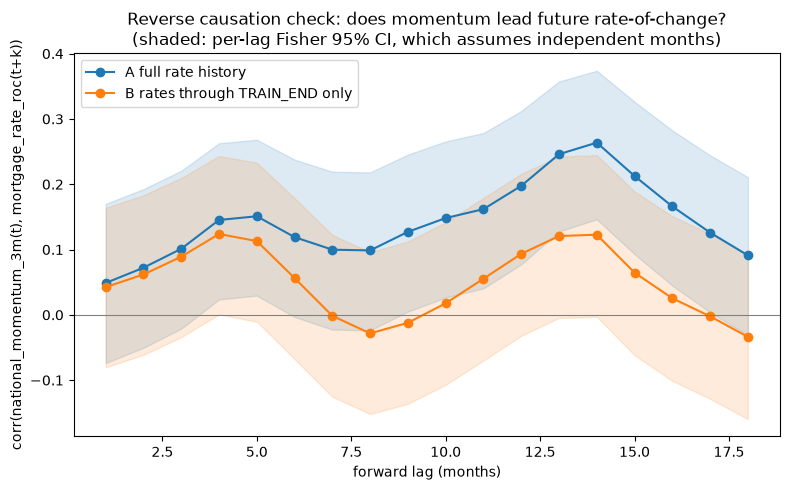

Saved outputs/reverse_causation_check.json, outputs/reverse_causation_lag_sweep.csv, and outputs/reverse_causation_lag_sweep.png


In [11]:
import matplotlib.pyplot as plt

os.makedirs("../outputs", exist_ok=True)
sweep.to_csv("../outputs/reverse_causation_lag_sweep.csv", index=False)


def variant_summary(name):
    w = winners[name]
    return {
        "winning_lag_months": int(w["lag_months"]),
        "winning_correlation": float(w["correlation"]),
        "winning_ci_95_fisher": [float(w["ci_low"]), float(w["ci_high"])],
        "winning_ci_95_block_bootstrap": honest[name]["block_ci_95"],
        "winning_p_value_single_lag": float(w["p_value"]),
        "best_of_18_p_value": honest[name]["p_best_of_18"],
        "winning_n_rows": int(w["n_rows"]),
        "sign_matches_hypothesis": bool((w["correlation"] > 0) == (EXPECTED_SIGN == "positive")),
    }


summary = {
    "expected_sign": EXPECTED_SIGN,
    "national_momentum_window_months": NATIONAL_MOMENTUM_LAG_MONTHS,
    "national_aggregation": "median",
    "variants": {
        "A_full_rate_history": variant_summary("A full rate history"),
        "B_rates_through_train_end": variant_summary("B rates through TRAIN_END only"),
    },
    "best_of_18_method": "rate-of-change series circularly shifted by >= 24 months, 2000 resamples, seed 42",
    "block_bootstrap_method": "12-month blocks, 2000 resamples, seed 42",
}
with open("../outputs/reverse_causation_check.json", "w") as fh:
    json.dump(summary, fh, indent=2)

fig, ax = plt.subplots(figsize=(8, 5))
for name, g in sweep.groupby("variant"):
    line, = ax.plot(g["lag_months"], g["correlation"], marker="o", label=name)
    ax.fill_between(g["lag_months"], g["ci_low"], g["ci_high"], alpha=0.15, color=line.get_color())
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("forward lag (months)")
ax.set_ylabel("corr(national_momentum_3m(t), mortgage_rate_roc(t+k))")
ax.set_title("Reverse causation check: does momentum lead future rate-of-change?\n"
             "(shaded: per-lag Fisher 95% CI, which assumes independent months)")
ax.legend()
fig.tight_layout()
fig.savefig("../outputs/reverse_causation_lag_sweep.png", dpi=150)
plt.show()
print("Saved outputs/reverse_causation_check.json, "
      "outputs/reverse_causation_lag_sweep.csv, and "
      "outputs/reverse_causation_lag_sweep.png")

## 10. Findings

**Result: the feedback-loop explanation is not supported within the training period.** The
apparent support in the first version of this notebook came from mortgage rates after the end of
Train, from a single episode.

- **Variant B (rates through `TRAIN_END` only), the honest test.** The best of the 18 lags is
  4 months, r = 0.1238 (n = 254). On its own that lag looks significant: Fisher 95% CI
  [0.0007, 0.2432], block-bootstrap 95% CI [+0.007, +0.226]. But it was picked from 18 lags, and
  39% of randomly shifted rate series produce a best |r| at least as large (best-of-18 p = 0.39).
  So the Train-period data show no relationship beyond what chance alone produces. Lags 7 to 9
  and 17 to 18 are near zero or negative.
- **Variant A (full rate history), the original result.** The best lag is 14 months,
  r = 0.2637 (Fisher 95% CI [0.1463, 0.3738], block-bootstrap [+0.049, +0.369], n = 258), and it
  beats every one of the 2,000 shifted series (best-of-18 p < 0.001). But the gap between A and B
  comes from the last training months, the 2020 to 2021 price boom, paired with rates from
  2021-10 onward, which fall in the Embargo and Test windows and include the sharp 2022 hikes. At
  14 months, dropping those pairs takes r from 0.26 to 0.12. One boom-then-hike episode cannot
  separate housing feeding back into rates from the Federal Reserve reacting to general
  inflation, and it uses data the training-only rule is meant to exclude.
- **The "broad band" of significant lags is not independent evidence.** National momentum has a
  month-to-month autocorrelation of 0.92, so neighbouring lags are nearly the same calculation and
  a smooth band appears even without a real relationship. The best-of-18 test accounts for this.
- **The premise is also weaker than first thought.** This notebook set out to explain notebook
  06's negative sign (r = -0.0521). The merged team repo's quarter-level re-test (82 quarters,
  r = -0.145, 95% CI [-0.351, +0.074]) shows that sign is itself not reliable.
- **Recommended wording:** "No reliable evidence that home prices lead mortgage rates."
- **What this does not change:** the project's headline result is unaffected. Rate-of-change
  still showed no significant marginal contribution to decline-risk prediction once momentum is
  already known (notebooks 08 to 10). Notebook 10's Final write-up has been updated to match this
  result.